Load Surface Pressure and Build Dataset

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import MinMaxScaler

# 1. Kaggle paths
experiment_dir = Path("/kaggle/working")
results_dir = experiment_dir / "pressure_grid_search_e4000"
results_dir.mkdir(parents=True, exist_ok=True)

# 2. Find uploaded dataset
pressure_files = list(
    Path("/kaggle/input").rglob("pressure_nearest_5sites.pt")
)

model_files = list(
    Path("/kaggle/input").rglob("02_climate_model.ipynb")
)

if len(pressure_files) != 1:
    raise FileNotFoundError(
        f"Expected one pressure dataset, found: {pressure_files}"
    )

if len(model_files) != 1:
    raise FileNotFoundError(
        f"Expected one model notebook, found: {model_files}"
    )

data_path = pressure_files[0]
model_notebook = model_files[0]

# 3. Load pressure
dataset = torch.load(
    data_path, map_location="cpu", weights_only=True
)

pressure_raw = dataset["pressure_raw"].numpy()
all_indices = dataset["location_indices"]

# Use the 4 locations in the author's pressure script
location_indices = [0, 5000, 10000, 20000]
selected_cols = [all_indices.index(i) for i in location_indices]

raw = pressure_raw[:, selected_cols]
input_dim = raw.shape[1]

# 4. Grid Search configuration
patch_lengths = [120]
horizons = [10, 15, 20, 25, 30]
d_models = [8, 16, 24, 32, 40, 48]

epochs = 4000
learning_rate = 3e-4
lyap_weight = 0.1
seed = 7

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 5. Build sliding windows
def build_pressure_dataset(raw, patch_len, horizon):
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(raw[:400])

    X, Y = [], []

    for i in range(len(scaled) - patch_len - horizon):
        X.append(scaled[i:i + patch_len])
        Y.append(
            scaled[i + patch_len:i + patch_len + horizon]
            .T.reshape(-1)
        )

    x_in = torch.tensor(np.stack(X), dtype=torch.float32)
    x_out = torch.tensor(np.stack(Y), dtype=torch.float32)

    return x_in, x_out, scaler

x_in, x_out, scaler = build_pressure_dataset(
    raw, patch_len=120, horizon=15
)

# 6. Environment summary
print("=== KAGGLE SURFACE PRESSURE ===")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("Dataset:", data_path)
print("Model notebook:", model_notebook)
print("Raw:", raw.shape)
print("X:", x_in.shape)
print("Y:", x_out.shape)
print("Epochs:", epochs)
print("Total runs:", len(patch_lengths) * len(horizons) * len(d_models) * 4)
print("Results:", results_dir)


=== KAGGLE SURFACE PRESSURE ===
GPU: Tesla T4
Dataset: /kaggle/input/datasets/tunnghanguynng/pressure/pressure_nearest_5sites.pt
Model notebook: /kaggle/input/datasets/tunnghanguynng/climate/02_climate_model.ipynb
Raw: (400, 4)
X: torch.Size([265, 120, 4])
Y: torch.Size([265, 60])
Epochs: 4000
Total runs: 120
Results: /kaggle/working/pressure_grid_search_e4000


Load DeepKoopFormer Models

In [3]:
import ast
import json
from pathlib import Path

model_notebook = Path(
    "/kaggle/input/datasets/tunnghanguynng/climate/02_climate_model.ipynb"
)

with open(model_notebook, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Extract definitions without executing dataset/training code
allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.ClassDef,
    ast.FunctionDef,
    ast.AsyncFunctionDef
)

definitions = []
class_names = []

for cell in notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = cell["source"]
    if isinstance(source, list):
        source = "".join(source)

    if not source.strip():
        continue

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, allowed_nodes):
            definitions.append(node)

            if isinstance(node, ast.ClassDef):
                class_names.append(node.name)

# Execute only imports, classes and functions
module = ast.Module(body=definitions, type_ignores=[])
ast.fix_missing_locations(module)

exec(
    compile(module, str(model_notebook), "exec"),
    globals()
)

# Model factory
def create_model(model_name, patch_len, horizon, d_model):
    if model_name == "LSTM":
        return SimpleLSTMForecaster(
            input_dim, d_model, 2, horizon
        )

    if model_name == "PatchTST":
        return Koopformer_PatchTST(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    if model_name == "Autoformer":
        return Koopformer_Autoformer(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    if model_name == "Informer":
        return Koopformer_Informer(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    raise ValueError(f"Unknown model: {model_name}")

# Verify model initialization
model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]

print("=== LOADED MODEL DEFINITIONS ===")
print("Classes found:", class_names)

for name in model_names:
    model = create_model(
        name, patch_len=120, horizon=15, d_model=8
    )

    parameters = sum(p.numel() for p in model.parameters())
    print(f"{name:<12} Parameters: {parameters:,}")

    del model

print("\nAll four models initialized successfully.")


=== LOADED MODEL DEFINITIONS ===
Classes found: ['StrictStableKoopmanOperator', 'SinCosPosEnc', 'PatchEmbed1D', 'SeriesDecomp', 'PatchTST_Backbone', 'Koopformer_PatchTST', 'SimpleAutoformer', 'Koopformer_Autoformer', 'InformerSparse', 'Koopformer_Informer', 'SimpleLSTMForecaster']
LSTM         Parameters: 1,564
PatchTST     Parameters: 10,412
Autoformer   Parameters: 13,063
Informer     Parameters: 10,404

All four models initialized successfully.


Training Function (DeepKoopFormer)

In [4]:
import torch.nn as nn
import torch.optim as optim

def set_seed(seed=7):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(seed)

def _nested_getattr(obj, path):
    for p in path.split("."):
        obj = getattr(obj, p, None)
        if obj is None:
            return None
    return obj

def train_pressure_model(
    model, x_in, x_out,
    epochs=4000, lr=3e-4,
    koop_attr="koop", lyap_weight=0.1
):
    model = model.to(device)
    x_in = x_in.to(device)
    x_out = x_out.to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()

    losses, eigs = [], []

    # Initialize Lyapunov matrix
    with torch.no_grad():
        try:
            _, z, z_next = model(
                x_in[:1], return_latents=True
            )
        except ValueError:
            z = z_next = torch.zeros(
                1, model.fc.in_features, device=device
            )

    P = torch.eye(z.shape[1], device=device)

    for ep in range(epochs):
        model.train()
        optimizer.zero_grad()

        pred, z, z_next = model(
            x_in, return_latents=True
        )

        pred_loss = mse(pred, x_out)

        if lyap_weight:
            zp = torch.einsum("bi,ij->bj", z, P)
            znp = torch.einsum("bi,ij->bj", z_next, P)

            lyap = torch.relu(
                (znp * z_next).sum(1)
                - (zp * z).sum(1)
            ).mean()
        else:
            lyap = torch.zeros(1, device=device)

        loss = pred_loss + lyap_weight * lyap

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        obj = (
            _nested_getattr(model, koop_attr)
            if koop_attr else None
        )

        eig_raw = (
            obj.S_raw
            if isinstance(obj, StrictStableKoopmanOperator)
            else None
        )

        eigs.append(
            0.0 if eig_raw is None
            else torch.sigmoid(eig_raw).abs().max().item()
        )

        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(
                f"Epoch {ep:>4}/{epochs} "
                f"MSE {pred_loss.item():.5f} "
                f"Lyap {(lyap_weight * lyap).item():.5f}"
            )

    # Final predictions on training windows
    model.eval()

    with torch.no_grad():
        predictions = model(x_in).cpu().numpy()

    return predictions, np.array(losses), np.array(eigs)


Surface Pressure Grid Search (4000 Epochs)

In [5]:
import gc
import itertools

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metrics_path = results_dir / "metrics.csv"

# All 120 configurations
configs = list(itertools.product(
    patch_lengths,
    horizons,
    d_models,
    model_names
))

if device.type != "cuda":
    raise RuntimeError(
        "Grid Search requires a CUDA GPU. "
        "Run this notebook on Kaggle GPU."
    )

results_dir.mkdir(parents=True, exist_ok=True)

# Fixed seed for reproducible sequential training
set_seed(seed)

records = {}

def checkpoint_path(p, h, d, name):
    return results_dir / f"{name.lower()}_p{p}_h{h}_d{d}.pt"

def save_metrics():
    df = pd.DataFrame(
        list(records.values()),
        columns=[
            "Model", "PatchLen", "Horizon",
            "d_model", "MSE", "MAE"
        ]
    )
    temp_path = metrics_path.with_suffix(".csv.tmp")
    df.to_csv(temp_path, index=False)
    temp_path.replace(metrics_path)

# Restore completed configurations
completed = 0

for p, h, d, name in configs:
    path = checkpoint_path(p, h, d, name)

    if not path.exists():
        break

    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )

    assert ckpt["epochs"] == epochs
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == h
    assert ckpt["d_model"] == d
    assert ckpt["model"] == name

    records[(p, h, d, name)] = {
        "Model": name,
        "PatchLen": p,
        "Horizon": h,
        "d_model": d,
        "MSE": ckpt["mse"],
        "MAE": ckpt["mae"]
    }

    completed += 1

    # Restore random state from last completed run
    torch.set_rng_state(ckpt["rng_torch"])

    if ckpt["rng_cuda"]:
        torch.cuda.set_rng_state_all(ckpt["rng_cuda"])

# Avoid silently continuing from inconsistent checkpoints
for p, h, d, name in configs[completed:]:
    if checkpoint_path(p, h, d, name).exists():
        raise RuntimeError(
            "Non-sequential checkpoints detected. "
            "Check the results directory before resuming."
        )

save_metrics()

print("=== SURFACE PRESSURE GRID SEARCH ===")
print("Device:", device)
print("Epochs per model:", epochs)
print("Total configurations:", len(configs))
print("Completed:", completed)
print("Remaining:", len(configs) - completed)
print("Results:", results_dir)

# Train remaining configurations
for idx, (p, h, d, name) in enumerate(
    configs[completed:], start=completed + 1
):
    print(
        f"\n[{idx}/{len(configs)}] "
        f"{name} | P={p}, H={h}, d_model={d}"
    )

    x_train, y_train, _ = build_pressure_dataset(
        raw, patch_len=p, horizon=h
    )

    model = create_model(
        name, patch_len=p, horizon=h, d_model=d
    )

    is_lstm = name == "LSTM"

    pred, loss, eig = train_pressure_model(
        model,
        x_train,
        y_train,
        epochs=epochs,
        lr=learning_rate,
        koop_attr=None if is_lstm else "koop",
        lyap_weight=0.0 if is_lstm else lyap_weight
    )

    truth = y_train.numpy()
    error = pred - truth

    mse_value = float(np.mean(error ** 2))
    mae_value = float(np.mean(np.abs(error)))

    # Save final model, predictions and training curves
    ckpt = {
        "model": name,
        "model_state_dict": model.cpu().state_dict(),
        "pred": torch.from_numpy(pred.copy()),
        "truth": torch.from_numpy(truth.copy()),
        "loss": torch.from_numpy(loss.copy()),
        "eig": torch.from_numpy(eig.copy()),
        "mse": mse_value,
        "mae": mae_value,
        "patch_len": p,
        "horizon": h,
        "d_model": d,
        "input_dim": input_dim,
        "epochs": epochs,
        "rng_torch": torch.get_rng_state(),
        "rng_cuda": torch.cuda.get_rng_state_all()
    }

    path = checkpoint_path(p, h, d, name)
    temp_path = path.with_suffix(".pt.tmp")

    torch.save(ckpt, temp_path)
    temp_path.replace(path)

    # Update metrics after every completed run
    records[(p, h, d, name)] = {
        "Model": name,
        "PatchLen": p,
        "Horizon": h,
        "d_model": d,
        "MSE": mse_value,
        "MAE": mae_value
    }

    save_metrics()

    print(
        f"Saved {name}: "
        f"MSE={mse_value:.6f}, "
        f"MAE={mae_value:.6f}"
    )

    del model, x_train, y_train, pred, loss, eig, ckpt
    gc.collect()
    torch.cuda.empty_cache()

print("\n=== GRID SEARCH COMPLETE ===")
print("Completed runs:", len(records))
print("Metrics saved:", metrics_path)


=== SURFACE PRESSURE GRID SEARCH ===
Device: cuda
Epochs per model: 4000
Total configurations: 120
Completed: 89
Remaining: 31
Results: /kaggle/working/pressure_grid_search_e4000

[90/120] PatchTST | P=120, H=25, d_model=40
Epoch    0/4000 MSE 0.36391 Lyap 0.00000
Epoch  400/4000 MSE 0.02394 Lyap 0.00000
Epoch  800/4000 MSE 0.01250 Lyap 0.00000
Epoch 1200/4000 MSE 0.00803 Lyap 0.00000
Epoch 1600/4000 MSE 0.00804 Lyap 0.00000
Epoch 2000/4000 MSE 0.00525 Lyap 0.00000
Epoch 2400/4000 MSE 0.00443 Lyap 0.00000
Epoch 2800/4000 MSE 0.00358 Lyap 0.00000
Epoch 3200/4000 MSE 0.00618 Lyap 0.00000
Epoch 3600/4000 MSE 0.00397 Lyap 0.00000
Epoch 3999/4000 MSE 0.00310 Lyap 0.00000
Saved PatchTST: MSE=0.002028, MAE=0.033656

[91/120] Autoformer | P=120, H=25, d_model=40
Epoch    0/4000 MSE 0.31911 Lyap 0.00000
Epoch  400/4000 MSE 0.02144 Lyap 0.00000
Epoch  800/4000 MSE 0.01315 Lyap 0.00000
Epoch 1200/4000 MSE 0.00726 Lyap 0.00000
Epoch 1600/4000 MSE 0.00525 Lyap 0.00000
Epoch 2000/4000 MSE 0.00444 Ly

Surface Pressure Grid Search Heatmaps (4000 Epochs)

=== SURFACE PRESSURE: 4000 EPOCHS ===
Metrics: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\pressure_grid_search_e4000\metrics.csv
Total runs: 120
Checkpoints: 120


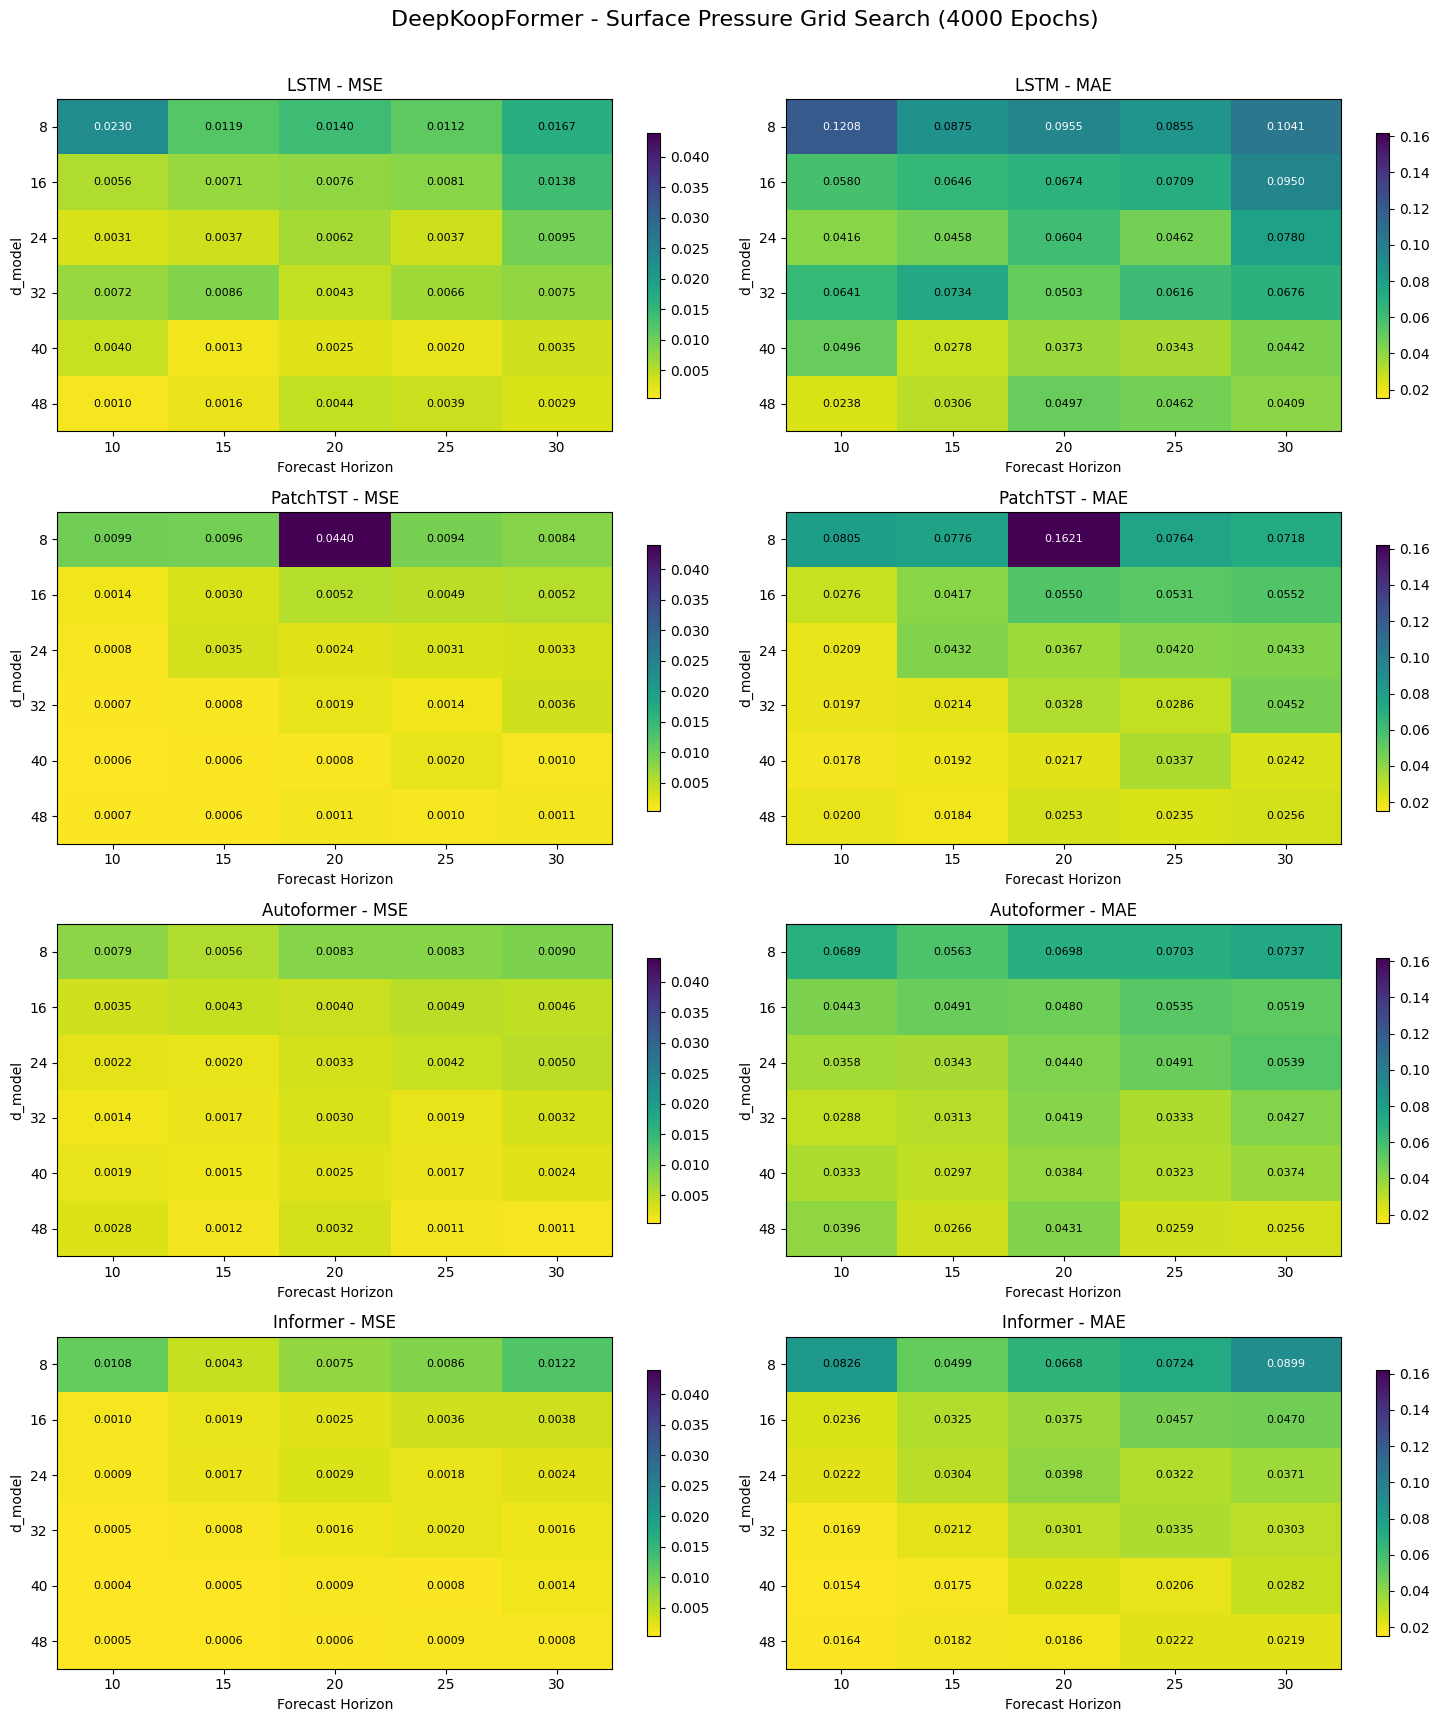

Figure saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\pressure_grid_search_e4000\figure5_pressure_heatmaps_e4000.png

=== BEST MSE PER MODEL ===
     Model  PatchLen  Horizon  d_model      MSE      MAE
  Informer       120       10       40 0.000427 0.015375
  PatchTST       120       10       40 0.000553 0.017838
      LSTM       120       10       48 0.000975 0.023775
Autoformer       120       30       48 0.001096 0.025605


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Locate local results
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "experiments" / "02_climate").is_dir()
)

results_dir = (
    project_root / "experiments" / "02_climate"
    / "results" / "pressure_grid_search_e4000"
)

metrics_path = results_dir / "metrics.csv"

if not metrics_path.is_file():
    raise FileNotFoundError(metrics_path)

metrics = pd.read_csv(metrics_path)

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
d_models = [8, 16, 24, 32, 40, 48]
horizons = [10, 15, 20, 25, 30]
metric_names = ["MSE", "MAE"]

# 2. Verify all 120 configurations
expected = {
    (m, d, h)
    for m in model_names
    for d in d_models
    for h in horizons
}

actual = set(zip(
    metrics["Model"],
    metrics["d_model"],
    metrics["Horizon"]
))

assert len(metrics) == 120, f"Expected 120 rows, got {len(metrics)}"
assert actual == expected, f"Missing configurations: {expected - actual}"
assert (metrics["PatchLen"] == 120).all()
assert metrics[metric_names].notna().all().all()

checkpoints = list(results_dir.glob("*_p120_h*_d*.pt"))
assert len(checkpoints) == 120, (
    f"Expected 120 checkpoints, found {len(checkpoints)}"
)

print("=== SURFACE PRESSURE: 4000 EPOCHS ===")
print("Metrics:", metrics_path)
print("Total runs:", len(metrics))
print("Checkpoints:", len(checkpoints))

# 3. Shared color scales across models
scales = {
    metric: (metrics[metric].min(), metrics[metric].max())
    for metric in metric_names
}

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

# 4. Plot MSE and MAE
for row, model_name in enumerate(model_names):
    model_data = metrics[metrics["Model"] == model_name]

    for col, metric_name in enumerate(metric_names):
        ax = axes[row, col]

        heatmap_data = model_data.pivot(
            index="d_model",
            columns="Horizon",
            values=metric_name
        ).reindex(index=d_models, columns=horizons)

        values = heatmap_data.to_numpy()
        vmin, vmax = scales[metric_name]

        im = ax.imshow(
            values,
            cmap="viridis_r",
            aspect="auto",
            vmin=vmin,
            vmax=vmax
        )

        for i in range(len(d_models)):
            for j in range(len(horizons)):
                value = values[i, j]

                ax.text(
                    j, i, f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if im.norm(value) > 0.5 else "black"
                )

        ax.set_xticks(range(len(horizons)), horizons)
        ax.set_yticks(range(len(d_models)), d_models)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("d_model")
        ax.set_title(f"{model_name} - {metric_name}")

        fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "DeepKoopFormer - Surface Pressure Grid Search (4000 Epochs)",
    fontsize=16, y=1.01
)

plt.tight_layout()

save_path = results_dir / "figure5_pressure_heatmaps_e4000.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", save_path)

# 5. Best configuration of each model
print("\n=== BEST MSE PER MODEL ===")

best = (
    metrics.loc[metrics.groupby("Model")["MSE"].idxmin()]
    [["Model", "PatchLen", "Horizon", "d_model", "MSE", "MAE"]]
    .sort_values("MSE")
)

print(best.to_string(index=False))


Reproduce Figure 6: Surface Pressure Forecasting

c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


LSTM         MSE=0.011942 MAE=0.087482
PatchTST     MSE=0.009576 MAE=0.077633
Autoformer   MSE=0.005623 MAE=0.056345
Informer     MSE=0.004309 MAE=0.049894


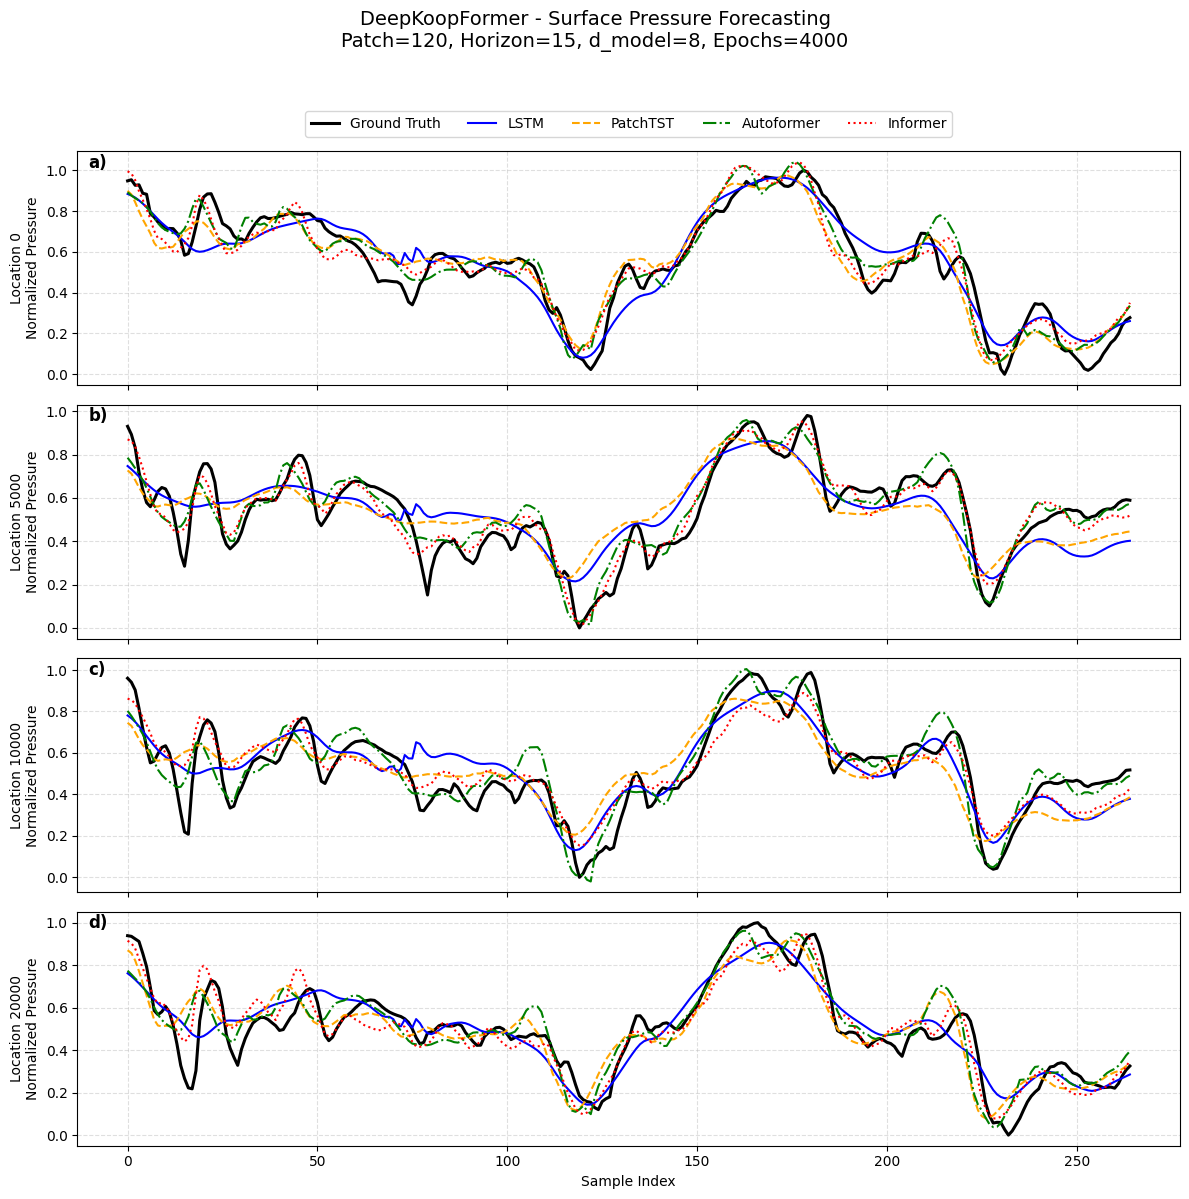


Samples: 265
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\pressure_grid_search_e4000\figure6_pressure_forecasting_e4000.png


In [2]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Local result directory
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "experiments" / "02_climate").is_dir()
)

results_dir = (
    project_root / "experiments" / "02_climate"
    / "results" / "pressure_grid_search_e4000"
)

# 2. Figure 6 configuration
P, H, D = 120, 15, 8
location_indices = [0, 5000, 10000, 20000]
F = len(location_indices)

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
results = {}

# 3. Load saved checkpoints
for name in model_names:
    path = results_dir / f"{name.lower()}_p{P}_h{H}_d{D}.pt"

    if not path.is_file():
        raise FileNotFoundError(path)

    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )

    assert ckpt["epochs"] == 4000
    assert ckpt["patch_len"] == P
    assert ckpt["horizon"] == H
    assert ckpt["d_model"] == D
    assert ckpt["input_dim"] == F

    results[name] = ckpt

    print(
        f"{name:<12} "
        f"MSE={ckpt['mse']:.6f} "
        f"MAE={ckpt['mae']:.6f}"
    )

# 4. Prepare ground truth and predictions
truth_tensor = results["LSTM"]["truth"]
N = truth_tensor.shape[0]

assert truth_tensor.shape == (N, F * H)

ground_truth = (
    truth_tensor.detach().cpu().numpy()
    .reshape(N, F, H)[:, :, 0]
)

predictions = {}

for name, ckpt in results.items():
    assert ckpt["pred"].shape == (N, F * H)

    assert torch.allclose(
        ckpt["truth"], truth_tensor,
        atol=1e-6, rtol=1e-6
    ), f"Ground truth mismatch: {name}"

    predictions[name] = (
        ckpt["pred"].detach().cpu().numpy()
        .reshape(N, F, H)[:, :, 0]
    )

# 5. Plot Figure 6
styles = {
    "LSTM":       {"color": "blue", "linestyle": "-"},
    "PatchTST":   {"color": "orange", "linestyle": "--"},
    "Autoformer": {"color": "green", "linestyle": "-."},
    "Informer":   {"color": "red", "linestyle": ":"}
}

fig, axes = plt.subplots(
    F, 1, figsize=(12, 12), sharex=True
)

for site, ax in enumerate(axes):

    ax.plot(
        np.arange(N),
        ground_truth[:, site],
        color="black",
        linewidth=2.2,
        label="Ground Truth"
    )

    for name in model_names:
        ax.plot(
            np.arange(N),
            predictions[name][:, site],
            linewidth=1.5,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(
        f"Location {location_indices[site]}\nNormalized Pressure"
    )

    ax.grid(True, linestyle="--", alpha=0.4)

    ax.text(
        0.01, 0.93,
        f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold"
    )

axes[0].legend(
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20)
)

axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "DeepKoopFormer - Surface Pressure Forecasting\n"
    "Patch=120, Horizon=15, d_model=8, Epochs=4000",
    fontsize=14,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.965])

save_path = results_dir / "figure6_pressure_forecasting_e4000.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSamples:", N)
print("Saved:", save_path)
